# 🧹 Data Cleaning & Preprocessing Pipeline
## UCS321 - Machine Learning Project | Problem Statement 9 (Telecom Customer Churn)
---

### 🎯 Pipeline Requirements & Architecture
1. **Target Leakage & Irrelevant Column Removal**:
   - `customer`: Arbitrary identifier (zero generalizable predictive signal).
   - `calibrat`: Tournament 50/50 training sample indicator (direct artificial sampling artifact).
   - `churndep`: Target duplicate with 31,047 missing values.
2. **Feature & Target Separation**:
   - Feature Matrix ($X$): 66 predictor attributes.
   - Target Vector ($y$): Binary ground truth `churn` ($0$ = Retained, $1$ = Churned).
3. **Accurate Feature Typing**:
   - **32 Binary Categorical Flags** ($0$ or $1$, representing demographic flags, service options, lifestyle).
   - **34 Continuous / Count Numerical Variables** (usage, billing amounts, tenure, device age).
4. **80:20 Stratified Train-Test Split**:
   - Preserving class proportion (~71% non-churn vs ~29% churn) across both partitions.
5. **Leakage-Free Preprocessing (`ColumnTransformer`)**:
   - Continuous Pipeline: Robust Median Imputation (`SimpleImputer(strategy='median')`) + Standardization (`StandardScaler()`).
   - Binary Pipeline: Kept unscaled (`passthrough`) to maintain sparsity and true binary semantics.
   - **Strict Fit-Transform Rule**: Preprocessors are fit **ONLY** on the training set, then applied to the test set.
6. **Artifact Persistence**:
   - Export processed training & testing datasets to `../data/processed/`.
   - Export serialized transformer pipeline to `../models/preprocessor.joblib`.



## 📦 Step 1: Environment Setup & Library Imports


In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

print("[+] Essential preprocessing libraries successfully imported!")



[+] Essential preprocessing libraries successfully imported!


## 📂 Step 2: Data Ingestion & Quality Audit


In [2]:
DATA_PATH = '../data/raw/cell2cell.csv'
df_raw = pd.read_csv(DATA_PATH)

print(f"📊 Dataset Dimensions: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"🔍 Exact Duplicate Rows: {df_raw.duplicated().sum()}")
df_raw.head(3)



📊 Dataset Dimensions: 71,047 rows x 70 columns
🔍 Exact Duplicate Rows: 0


,customer,calibrat,churn,churndep,revenue,mou,recchrge,directas,overage,roam,...,retaccpt,newcelly,newcelln,refer,incmiss,income,mcycle,setprcm,setprc,retcall
0,1000002,0,0,NaN,57.492500,482.75,37.424999,0.2475,22.75,0.0,...,0,0,1,0,0,5,0,0,149.989990,0
1,1000006,0,0,NaN,82.275002,1312.25,75.000000,1.2375,0.00,0.0,...,0,1,0,0,0,6,0,0,9.989998,0
2,1000010,0,0,NaN,31.662500,25.50,29.990000,0.2475,0.00,0.0,...,0,0,1,0,0,9,0,0,29.989990,0


## 🛡️ Step 3: Prevent Target Leakage & Separate Features ($X$) and Target ($y$)

### Critical Machine Learning Safeguards:
1. `customer`: Random ID number. If kept, decision trees could split on specific customer IDs instead of learning behavioral patterns.
2. `calibrat`: A competition artifact indicating the 50/50 training subset. Using this in real-world deployment would be impossible and constitutes direct data leakage.
3. `churndep`: An incomplete duplicate of `churn` with 31,047 missing values.

We drop all three columns and isolate `churn` as the single ground truth target vector.


In [3]:
LEAKAGE_AND_ID_COLS = ['customer', 'calibrat', 'churndep']
TARGET_COL = 'churn'

# Verify presence
for col in LEAKAGE_AND_ID_COLS + [TARGET_COL]:
    assert col in df_raw.columns, f"Missing required column: {col}"

# Separate X and y
y = df_raw[TARGET_COL].copy().astype(int)
X = df_raw.drop(columns=LEAKAGE_AND_ID_COLS + [TARGET_COL]).copy()

print(f"[+] Target variable shape (y): {y.shape}")
print(f"[+] Feature matrix shape (X): {X.shape[0]:,} rows x {X.shape[1]} features")
print(f"[+] Removed leakage columns: {LEAKAGE_AND_ID_COLS}")



[+] Target variable shape (y): (71047,)
[+] Feature matrix shape (X): 71,047 rows x 66 features
[+] Removed leakage columns: ['customer', 'calibrat', 'churndep']


## 🔬 Step 4: Correct Feature Identification (Numerical vs Categorical Flags)

In telecom data, binary categorical indicators (e.g. `children`, `credita`, `refurb`, `webcap`, `retcall`) should **NOT** be normalized or scaled with `StandardScaler`. Standardizing $0/1$ flags to arbitrary floats:
1. Destroys interpretability in logistic regression coefficients and decision tree splits.
2. Destroys natural sparsity.

We categorize all 66 features into:
- **32 Binary Categorical Features** ($0$ or $1$)
- **34 Continuous / Count Numerical Features**


In [4]:
binary_cols = [c for c in X.columns if X[c].dropna().isin([0, 1]).all()]
numerical_cols = [c for c in X.columns if c not in binary_cols]

print(f"[+] Identified Binary Flags: {len(binary_cols)} features")
print(f"[+] Identified Continuous / Numerical: {len(numerical_cols)} features")
assert len(binary_cols) + len(numerical_cols) == X.shape[1], "Feature count mismatch!"

# Display categorization summary
feature_summary = pd.DataFrame({
    'Feature Type': ['Binary Categorical Flags (0/1)', 'Continuous / Numerical'],
    'Count': [len(binary_cols), len(numerical_cols)],
    'Examples': [
        ', '.join(binary_cols[:5]) + '...',
        ', '.join(numerical_cols[:5]) + '...'
    ]
})
feature_summary



[+] Identified Binary Flags: 32 features
[+] Identified Continuous / Numerical: 34 features


,Feature Type,Count,Examples
0,Binary Categorical Flags (0/1),32,"children, credita, creditaa, prizmrur, prizmub..."
1,Continuous / Numerical,34,"revenue, mou, recchrge, directas, overage..."


## ✂️ Step 5: 80:20 Stratified Train-Test Split

### ⚠️ Golden Rule of Machine Learning:
To prevent **Data Leakage**, the train-test split must occur **BEFORE** any imputation or scaling.
- If we imputed or scaled before splitting, information from the test set (mean, median, standard deviation) would leak into the training process.
- We use **stratified sampling (`stratify=y`)** so that both splits contain the exact same churn ratio (~71% non-churn vs ~29% churn).


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"📊 Training Set Dimensions : {X_train.shape[0]:,} rows ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"📊 Testing Set Dimensions  : {X_test.shape[0]:,} rows ({X_test.shape[0]/len(X)*100:.1f}%)")

# Verify stratification consistency
strat_df = pd.DataFrame({
    'Original Dataset (%)': y.value_counts(normalize=True) * 100,
    'Train Split (%)': y_train.value_counts(normalize=True) * 100,
    'Test Split (%)': y_test.value_counts(normalize=True) * 100
})
strat_df.index = ['Retained (0)', 'Churned (1)']
strat_df.round(2)



📊 Training Set Dimensions : 56,837 rows (80.0%)
📊 Testing Set Dimensions  : 14,210 rows (20.0%)


,Original Dataset (%),Train Split (%),Test Split (%)
Retained (0),70.99,70.99,70.99
Churned (1),29.01,29.01,29.01


## ⚙️ Step 6: Construct Scikit-Learn `ColumnTransformer` Pipeline

### Strategy:
1. **Numerical Features (34)**:
   - `SimpleImputer(strategy='median')`: Replaces missing values with the median of the feature (robust to heavy skews and outliers in telecom revenue/minutes).
   - `StandardScaler()`: Centers to mean 0 and scales to unit variance.
2. **Binary Features (32)**:
   - `passthrough`: Preserved untouched as $\{0, 1\}$ integer values to retain direct business interpretability and optimal decision-tree thresholding.


In [6]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

bin_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),  # Safeguard for any unseen missing flags
    ('passthrough', 'passthrough')
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, numerical_cols),
        ('bin', bin_pipeline, binary_cols)
    ],
    remainder='drop'
)

print("[+] ColumnTransformer architecture configured:")
preprocessor



[+] ColumnTransformer architecture configured:


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

## 🔒 Step 7: Leakage-Free Preprocessor Fitting & Transformation

### 🛡️ Preventing Data Leakage:
- `preprocessor.fit(X_train)`: Calculates median, mean ($\mu$), and standard deviation ($\sigma$) **STRICTLY on the training partition**.
- `preprocessor.transform(X_train)`: Transforms the training set.
- `preprocessor.transform(X_test)`: Transforms the test set using the **training parameters** without learning anything from the test set.


In [7]:
# Fit strictly on X_train
preprocessor.fit(X_train)

# Transform both partitions
X_train_proc_arr = preprocessor.transform(X_train)
X_test_proc_arr = preprocessor.transform(X_test)

# Preserve column ordering and clean DataFrame structure
feature_names_out = numerical_cols + binary_cols

X_train_processed = pd.DataFrame(X_train_proc_arr, columns=feature_names_out, index=X_train.index)
X_test_processed = pd.DataFrame(X_test_proc_arr, columns=feature_names_out, index=X_test.index)

print(f"[+] Processed X_train shape: {X_train_processed.shape}")
print(f"[+] Processed X_test shape : {X_test_processed.shape}")
print(f"[+] Null values remaining in X_train: {X_train_processed.isnull().sum().sum()}")
print(f"[+] Null values remaining in X_test : {X_test_processed.isnull().sum().sum()}")



[+] Processed X_train shape: (56837, 66)
[+] Processed X_test shape : (14210, 66)
[+] Null values remaining in X_train: 0
[+] Null values remaining in X_test : 0


## 📊 Step 8: Preprocessing Quality & Distribution Verification
We inspect sample numerical features (now standardized) vs binary features (preserved in $\{0, 1\}$).


C:\Users\gumbh\AppData\Local\Temp\ipykernel_23420\4267646761.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=X_train_processed['webcap'], ax=axes[1], palette=['#2b5c8f', '#d95f02'])


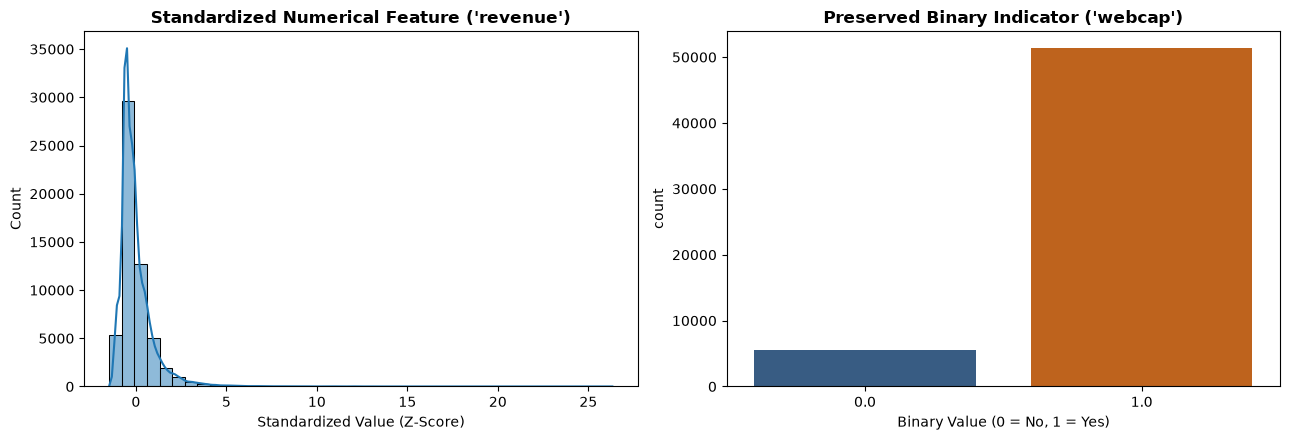

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Numerical feature after scaling
sns.histplot(X_train_processed['revenue'], kde=True, ax=axes[0], color='#1f77b4', bins=40)
axes[0].set_title("Standardized Numerical Feature ('revenue')", fontweight='bold')
axes[0].set_xlabel("Standardized Value (Z-Score)")

# Binary feature preserved
sns.countplot(x=X_train_processed['webcap'], ax=axes[1], palette=['#2b5c8f', '#d95f02'])
axes[1].set_title("Preserved Binary Indicator ('webcap')", fontweight='bold')
axes[1].set_xlabel("Binary Value (0 = No, 1 = Yes)")

plt.tight_layout()
plt.show()



## 💾 Step 9: Serialize Processed Datasets & Preprocessing Pipeline

We save all processed partitions and serialized preprocessor for seamless integration into Model Training.


In [9]:
PROCESSED_DIR = '../data/processed'
MODELS_DIR = '../models'
os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

# 1. Save processed feature matrices and target vectors
X_train_processed.to_csv(f"{PROCESSED_DIR}/X_train_processed.csv", index=False)
X_test_processed.to_csv(f"{PROCESSED_DIR}/X_test_processed.csv", index=False)
y_train.to_csv(f"{PROCESSED_DIR}/y_train.csv", index=False)
y_test.to_csv(f"{PROCESSED_DIR}/y_test.csv", index=False)

# 2. Save fitted preprocessor pipeline with joblib
PIPELINE_PATH = f"{MODELS_DIR}/preprocessor.joblib"
joblib.dump(preprocessor, PIPELINE_PATH)

# 3. Save feature metadata JSON
metadata = {
    "total_samples": len(df_raw),
    "train_samples": len(X_train_processed),
    "test_samples": len(X_test_processed),
    "features_total": len(feature_names_out),
    "numerical_features_count": len(numerical_cols),
    "binary_features_count": len(binary_cols),
    "numerical_features": numerical_cols,
    "binary_features": binary_cols,
    "imputation_strategy": "median",
    "scaling_strategy": "StandardScaler (numerical only)",
    "target_variable": TARGET_COL,
    "train_churn_pct": float(y_train.mean() * 100),
    "test_churn_pct": float(y_test.mean() * 100)
}

with open(f"{PROCESSED_DIR}/preprocessing_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print(f"[+] Saved X_train_processed.csv : {os.path.getsize(f'{PROCESSED_DIR}/X_train_processed.csv') / (1024**2):.2f} MB")
print(f"[+] Saved X_test_processed.csv  : {os.path.getsize(f'{PROCESSED_DIR}/X_test_processed.csv') / (1024**2):.2f} MB")
print(f"[+] Saved y_train.csv & y_test.csv")
print(f"[+] Serialized pipeline to {PIPELINE_PATH}")
print(f"[+] Saved metadata to {PROCESSED_DIR}/preprocessing_metadata.json")
print("[+] Step 3: Data Cleaning & Preprocessing COMPLETED SUCCESSFULLY!")



[+] Saved X_train_processed.csv : 43.89 MB
[+] Saved X_test_processed.csv  : 10.97 MB
[+] Saved y_train.csv & y_test.csv
[+] Serialized pipeline to ../models/preprocessor.joblib
[+] Saved metadata to ../data/processed/preprocessing_metadata.json
[+] Step 3: Data Cleaning & Preprocessing COMPLETED SUCCESSFULLY!
